# JAFF

The network class is the core class of JAFF. It is resposible for creating the network object which contains all the properties of the network such as reactions, species and related metadata

In [3]:
from jaff import Network

net = Network("../networks/demos/demo1.jet")


░░█ ▄▀█ █▀▀ █▀▀
█▄█ █▀█ █▀░ █▀░

Just Another Friendly Format!

INFO     Loading network from /home/anish/External/programming/research/jaff/worktrees/enhancement-plotting/networks/demos/demo1.jet
INFO     Network label: demo1


Output()

Output()

INFO     Loaded 15 reactions
INFO     Loaded 2 photo-chemistry reactions
INFO     Variables found: av, crate, tgas
WARNING  Found undefined functions photorates
INFO     Sink: N2+
INFO     Sink: CH2
INFO     Sink: H2
INFO     Source: CH
WARNING  Sink detected
WARNING  Source detected
INFO     Network loaded successfully!


Now that the network is loaded, we can access different properties of the network using the `net` object

## Specie properties

`Network.species` contains a list of species objects which can be indexed like a normal list.
Each `species` object have theire own attributes like `name` and `mass`

In [4]:
from IPython.display import display, Markdown

table = r"""
| Name | Mass | Charge | Latex |
|------|------|--------|-------|
"""

for specie in net.species:
    table += (
        f"| {specie.name} "
        f"| {specie.mass:.5e} "
        f"| {specie.charge} "
        f"| ${specie.latex()}$ |\n"
    )

display(Markdown(table))


| Name | Mass | Charge | Latex |
|------|------|--------|-------|
| H+ | 1.67286e-24 | 1 | ${\rm H^{+}}$ |
| e- | 9.10938e-28 | -1 | ${\rm e^{-}}$ |
| H | 1.67377e-24 | 0 | ${\rm H}$ |
| C | 1.99447e-23 | 0 | ${\rm C}$ |
| C+ | 1.99438e-23 | 1 | ${\rm C^{+}}$ |
| CO+ | 4.65114e-23 | 1 | ${\rm CO^{+}}$ |
| CO | 4.65124e-23 | 0 | ${\rm CO}$ |
| O | 2.65676e-23 | 0 | ${\rm O}$ |
| CH2 | 2.32923e-23 | 0 | ${\rm CH_{2}}$ |
| CH | 2.16185e-23 | 0 | ${\rm CH}$ |
| N2 | 4.65173e-23 | 0 | ${\rm N_{2}}$ |
| N | 2.32587e-23 | 0 | ${\rm N}$ |
| N2+ | 4.65164e-23 | 1 | ${\rm N_{2}^{+}}$ |
| H2 | 3.34755e-24 | 0 | ${\rm H_{2}}$ |


## Reaction properties

Like `Network.species`, `Network.reactions` stores a list of reactions objects which can be accessed by their respective indices. `Reaction` objects contain their own attributes like `tmin` and `tmax` for the reaction

In [5]:
table = """
| Verbatim | LaTeX |
|----------|-------|
"""

for rxn in net.reactions:
    table += f"| `{rxn.verbatim}` | ${rxn.get_latex()}$ |\n"

display(Markdown(table))


| Verbatim | LaTeX |
|----------|-------|
| `H+ + e- -> H` | $${\rm H^{+}} + {\rm e^{-}}\,\to\,{\rm H}$$ |
| `H -> H+ + e-` | $${\rm H}\,\to\,{\rm H^{+}} + {\rm e^{-}}$$ |
| `C -> C+ + e-` | $${\rm C}\,\to\,{\rm C^{+}} + {\rm e^{-}}$$ |
| `C+ + e- -> C` | $${\rm C^{+}} + {\rm e^{-}}\,\to\,{\rm C}$$ |
| `CO+ + e- -> CO` | $${\rm CO^{+}} + {\rm e^{-}}\,\to\,{\rm CO}$$ |
| `C + O -> CO` | $${\rm C} + {\rm O}\,\to\,{\rm CO}$$ |
| `CO -> C + O` | $${\rm CO}\,\to\,{\rm C} + {\rm O}$$ |
| `CO -> CO+ + e-` | $${\rm CO}\,\to\,{\rm CO^{+}} + {\rm e^{-}}$$ |
| `H + _PHOTON -> H+ + e-` | $${\rm H} + {\rm \gamma}\,\to\,{\rm H^{+}} + {\rm e^{-}}$$ |
| `CH2 + _PHOTON -> CH + H` | $${\rm CH_{2}} + {\rm \gamma}\,\to\,{\rm CH} + {\rm H}$$ |
| `N2 + _CR -> N + N` | $${\rm N_{2}} + {\rm \_CR}\,\to\,{\rm N} + {\rm N}$$ |
| `N + N -> N2` | $${\rm N} + {\rm N}\,\to\,{\rm N_{2}}$$ |
| `CO + N2+ -> N2 + CO+` | $${\rm CO} + {\rm N_{2}^{+}}\,\to\,{\rm N_{2}} + {\rm CO^{+}}$$ |
| `H2 + e- -> H + H + e-` | $${\rm H_{2}} + {\rm e^{-}}\,\to\,{\rm H} + {\rm H} + {\rm e^{-}}$$ |
| `N2+ + e- -> N + N` | $${\rm N_{2}^{+}} + {\rm e^{-}}\,\to\,{\rm N} + {\rm N}$$ |


Individual reactions can be accessed in the following way

In [6]:
print(f"The first reaction in verbatim form:   {net.reactions[0].verbatim}")  # verbatim name of first reaction
print(f"The firse reaction in serealized form: {net.reactions[0].serialized}")

The first reaction in verbatim form:   H+ + e- -> H
The firse reaction in serealized form: H+.e-__H


The reaction rate coefficients can be accessed in speciefic programming languages using the `get_code` method

In [7]:
print(f"Rate coefficient in c:        {net.reactions[0].get_code(lang='c')}")  # rate in C format of first reaction
print(f"Rate coefficient in fortran:  {net.reactions[0].get_code(lang='fortran')}")  # rate in Fortran 90 format of first reaction

Rate coefficient in c:        ((tgas < 300.0) ? (
   2.6022447615079392e-10*pow(tgas, -0.75)
)
: (
   3.6100000000000002e-12
))
Rate coefficient in fortran:  merge(2.60224476150794d-10*tgas**(-0.75d0), 3.61d-12, tgas < 300.0d0)


In [8]:
# Check if the first reaction is the same as itself
print(f"Is the first reaction same as the first reaction: {net.reactions[0] == net.reactions[0]}")

# Check if the first reaction is the same as the second
print(f"Is the first reaction same as teh second reaction: {net.reactions[0] == net.reactions[1]}")  

Is the first reaction same as the first reaction: True
Is the first reaction same as teh second reaction: False


Reaction rate coefficients and flux expressions can be also be accessed

In [9]:
# Flux of first reaction in symbolic form
print(f"Flux expression for the first reaction: {net.reactions[0].get_flux_expression(rate_variable="krate")}")  

# Rate of first reaction in symbolic form
print("Rate coefficient for the first reaction: ")
net.reactions[0].rate

Flux expression for the first reaction: krate[0] * y[idx_hj] * y[idx_e]
Rate coefficient for the first reaction: 


Piecewise((2.60224476150794e-10/tgas**0.75, tgas < 300.0), (3.61e-12, True))

Cross-sections of certain photo reactions can also be plotted

## Code generation

Jaff also comes with code generation capabilities and comes with an in-built templating system to generate langauge specific code

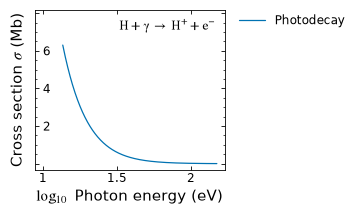

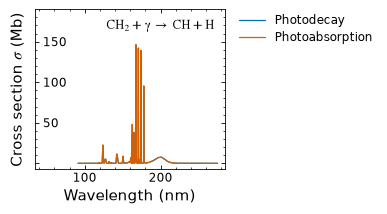

In [14]:
a1 = net.reactions.get(
    "H + _PHOTON -> H+ + e-", type="photo"
)  # get reaction by verbatim name
a1.plot_xsecs(processes="photodecay", yscale="linear")

a2 = net.reactions.get("CH2 + _PHOTON -> CH + H")  # get photodissociation reaction
_ = a2.plot_xsecs(energy_unit="nm", xscale="linear", yscale="linear", processes=["photodecay", "photo_absorption"])  # plot cross-sections

In [ ]:
! jaffgen --template fortran_dlsodes --network ../networks/demos/demo1.jet

In [ ]:
assert _exit_code == 0

Networks can can also be compared to each other

In [16]:
net2 = Network("../networks/demos/demo2.jet", label="very small network")


░░█ ▄▀█ █▀▀ █▀▀
█▄█ █▀█ █▀░ █▀░

Just Another Feisty Format!

INFO     Loading network from /home/anish/External/programming/research/jaff/worktrees/enhancement-plotting/networks/demos/demo2.jet
INFO     Network label: very small network


Output()

Output()

INFO     Loaded 2 reactions
INFO     Loaded 0 photo-chemistry reactions
INFO     Variables found: av, tgas
INFO     Network loaded successfully!


In [17]:
net.compare_reactions(net2)  # compare two networks

INFO     Comparing networks "demo1" and "very small network"...
INFO     Reactions not present in demo1:
 

INFO     Reactions not present in very small network:
C + O -> CO
CO -> C + O
H2 + e- -> H + H + e-
H+ + e- -> H
C -> C+ + e-
H + _PHOTON -> H+ + e-
CO + N2+ -> N2 + CO+
N2 + _CR -> N + N
CH2 + _PHOTON -> CH + H
C+ + e- -> C
N2+ + e- -> N + N
N + N -> N2
H -> H+ + e- 

INFO     Reactions present in both demo1 and very small network:
CO -> CO+ + e-
CO+ + e- -> CO 

INFO     2 reactions are common in both networks
INFO     0 reactions are missing in "demo1"
INFO     13 reactions are missing in "very small network"


In [18]:
net.compare_species(net2)  # compare species in two networks

INFO     Comparing species in networks "demo1" and "very small network"...
INFO     Species not present in demo1:
 

INFO     Species not present in very small network:
CH, N, O, C+, N2, H+, H2, N2+, C, CH2, H 

INFO     Species present in both demo1 and very small network:
e-, CO, CO+ 

INFO     3 species are common in both networks
INFO     0 species are missing in "demo1"
INFO     11 species are missing in "very small network"


Reactions rates can also be plotted

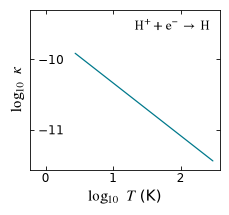

In [19]:
net.reactions[0].rate  # verbatim name of first reaction in COthin network
_ = net.reactions[0].plot_rate_coefficient()